# Lab: Classification with Bank Marketing Data

---

In this lab you will practice building and evaluating **classification models** using a real bank marketing dataset.

The data comes from direct marketing campaigns conducted by a Portuguese banking institution. The campaigns were based on phone calls, and the classification goal is to predict whether a client will subscribe to a term deposit.

We will use the official `bank.csv` sample from the **UCI Bank Marketing dataset**. It is a 10% random sample of the larger dataset and is useful here because we will train several KNN models while choosing a value of `k`.

**Source:** UCI Machine Learning Repository — Bank Marketing  
https://archive.ics.uci.edu/dataset/222/bank+marketing

**Target:** `y`
- `yes` = client subscribed to a term deposit
- `no` = client did not subscribe

### Data Dictionary

| Variable | Description |
|---|---|
| `age` | Client age |
| `job` | Type of job |
| `marital` | Marital status |
| `education` | Education level |
| `default` | Whether the client has credit in default |
| `balance` | Average yearly account balance, in euros |
| `housing` | Whether the client has a housing loan |
| `loan` | Whether the client has a personal loan |
| `contact` | Contact communication type |
| `day` | Day of the month of the last contact |
| `month` | Month of the last contact |
| `duration` | Duration of the last contact, in seconds |
| `campaign` | Number of contacts performed during the current campaign |
| `pdays` | Days since the client was last contacted in a previous campaign (`-1` means not previously contacted) |
| `previous` | Number of contacts performed before the current campaign |
| `poutcome` | Outcome of the previous marketing campaign |
| `y` | Whether the client subscribed to the term deposit (`yes` / `no`) |

#### Understanding the Bank Marketing Features

Think of each row as describing a client at the time of a contact in the **current marketing campaign**.

##### Timeline

```text
CLIENT INFORMATION — already known
│
├── age        → client's age
├── job        → occupation
├── marital    → marital status
├── education  → education level
├── default    → has credit in default?
├── balance    → account balance
├── housing    → has housing loan?
└── loan       → has personal loan?
│
│
▼
PREVIOUS MARKETING CAMPAIGN(S)
│
├── previous   → number of contacts made BEFORE the current campaign
├── poutcome   → outcome of the previous campaign
│
└── Last contact from a previous campaign
        │
        │
        │  pdays
        │  = number of days since this previous contact
        │
        ▼
CURRENT MARKETING CAMPAIGN
│
├── Current contact is about to take place
│
├── month      → month of the current contact
├── day        → day of the current contact
├── contact    → contact method (e.g. cellular / telephone)
├── campaign   → contact number during this campaign (includes the current contact)
│
│                 Example:
│                 Call 1 → Call 2 → Call 3
│                                      ↑
│                                campaign = 3
│
▼
CURRENT PHONE CALL
│
├── duration   → how long this current contact/call lasted
│
▼
CAMPAIGN OUTCOME
│
└── y          → Did the client subscribe to a term deposit?
    
```

In [254]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression

from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score,roc_curve,
                             ConfusionMatrixDisplay, RocCurveDisplay)
from imblearn.over_sampling import SMOTENC

### 1. Download and read in the Bank Marketing data.

Download the UCI Bank Marketing archive and extract `bank.csv`.

Then:

1. Read the CSV into a pandas dataframe.
2. Remember that this file uses `;` as the separator.
3. Display the first five rows.

In [255]:
bank_df=pd.read_csv('/content/bank.csv', sep=';')
bank_df.head(1000)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,38,blue-collar,married,secondary,no,1370,yes,no,cellular,11,may,472,2,-1,0,unknown,no
996,58,management,married,secondary,no,37,no,no,cellular,18,aug,84,11,-1,0,unknown,no
997,34,management,single,tertiary,no,673,yes,yes,cellular,20,nov,271,1,184,1,failure,no
998,40,services,married,secondary,no,-342,yes,no,unknown,26,may,754,1,-1,0,unknown,no


### 2. Conduct an initial exploration of the dataset.

Complete the following:

1. Check the shape of the dataset.
2. Inspect the data types and missing values.
3. Display summary statistics.
4. Check the distribution of the target variable `y`, including percentages.
5. Is this a balanced or imbalanced classification problem? Explain briefly.

In [256]:
# 1) Shape
bank_df.shape

(4521, 17)

In [257]:
# 2) Data types and missing values
bank_df.info()
print("--------------------------------------------------")
print("Missing values per column:")
print(bank_df.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        4521 non-null   int64 
 1   job        4521 non-null   object
 2   marital    4521 non-null   object
 3   education  4521 non-null   object
 4   default    4521 non-null   object
 5   balance    4521 non-null   int64 
 6   housing    4521 non-null   object
 7   loan       4521 non-null   object
 8   contact    4521 non-null   object
 9   day        4521 non-null   int64 
 10  month      4521 non-null   object
 11  duration   4521 non-null   int64 
 12  campaign   4521 non-null   int64 
 13  pdays      4521 non-null   int64 
 14  previous   4521 non-null   int64 
 15  poutcome   4521 non-null   object
 16  y          4521 non-null   object
dtypes: int64(7), object(10)
memory usage: 600.6+ KB
--------------------------------------------------
Missing values per column:
age          0
job   

In [258]:
# 3) Summary statistics (numerical and categorical)
display(bank_df.describe())
display(bank_df.describe(include='object'))

,age,balance,day,duration,campaign,pdays,previous
count,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000
mean,41.170095,1422.657819,15.915284,263.961292,2.793630,39.766645,0.542579
std,10.576211,3009.638142,8.247667,259.856633,3.109807,100.121124,1.693562
min,19.000000,-3313.000000,1.000000,4.000000,1.000000,-1.000000,0.000000
25%,33.000000,69.000000,9.000000,104.000000,1.000000,-1.000000,0.000000
50%,39.000000,444.000000,16.000000,185.000000,2.000000,-1.000000,0.000000
75%,49.000000,1480.000000,21.000000,329.000000,3.000000,-1.000000,0.000000
max,87.000000,71188.000000,31.000000,3025.000000,50.000000,871.000000,25.000000


,job,marital,education,default,housing,loan,contact,month,poutcome,y
count,4521,4521,4521,4521,4521,4521,4521,4521,4521,4521
unique,12,3,4,2,2,2,3,12,4,2
top,management,married,secondary,no,yes,no,cellular,may,unknown,no
freq,969,2797,2306,4445,2559,3830,2896,1398,3705,4000


In [259]:
# 4) Distribution of the target variable, with percentages
target_counts = bank_df['y'].value_counts()
target_pct = bank_df['y'].value_counts(normalize=True).mul(100).round(2)
display(pd.DataFrame({'count': target_counts, 'percentage (%)': target_pct}))

,count,percentage (%)
y,,
no,4000,88.48
yes,521,11.52


In [260]:
# Q5)

# This is an IMBALANCED classification problem.

# Only about 11.5% of clients subscribed ("yes", 521 clients) versus about 88.5% who did not("no", 4000 clients)

# minority class, so a model can look good on overall accuracy while still missing most of the clients we actually want to find.

### 3. Define the business problem and choose an evaluation metric.

Assume the bank wants to use the model to decide **which clients should be prioritized for future marketing calls**.

Answer the following:

1. What does a **False Positive** mean in this business problem? What is the cost of this error?
2. What does a **False Negative** mean? What is the cost of this error?
3. Assume the bank considers both errors important, which metric would you choose?
4. Why might **Accuracy** be misleading for this dataset?

#### Answers

**1. False Positive (FP):** the model predicts a client **will subscribe**, but the client **does not**. The bank prioritizes this client for a call and gets nothing from it. The cost is the wasted agent time and call-center resources, plus possible annoyance for a client who was never going to buy. The cost per error is relatively **low**.

**2. False Negative (FN):** the model predicts a client **will not subscribe**, but the client **would have**. The bank never calls (or deprioritizes) a client who would have opened a term deposit. The cost is **lost revenue and a lost customer opportunity**, which is usually **higher** than the cost of one extra phone call.

**3. Metric:** if both errors matter, I would choose the **F1 score**. It is the harmonic mean of Precision (which penalizes FPs) and Recall (which penalizes FNs), and it focuses on the positive ("yes") class. Balanced Accuracy and ROC AUC are useful supporting metrics.

**4. Why Accuracy is misleading:** about 88.5% of clients are "no". A useless model that predicts "no" for everyone would be about 88.5% accurate while finding **zero** subscribers (Recall = 0). Accuracy rewards the majority class and hides poor performance on the class we care about.

### 4. Check for information that would lead to data leakage.

The goal is to prioritize clients **before making the marketing call**.

Review the data dictionary and identify any variable that would only become known after the call has already taken place.

1. Which variable should be removed?
2. Why would keeping it create a data leakage / unrealistic prediction problem?
3. Drop the variable from the dataframe.

#### Answers:

**1. Variable to remove:** `duration`.

**2. Why it is leakage:** `duration` is the length of the *current* call, so it is only known **after** the call has happened. The goal is to decide **who to call before dialing**, so at prediction time this value does not exist. It is also strongly tied to the outcome (a client who hangs up in a few seconds almost never subscribes, and long calls tend to be the ones that end in a subscription). Keeping it would inflate the metrics and give a model that cannot be used in practice.

**3. Dropping it:** done in the code cell below.

In [261]:
# 3. Drop the leaky variable
bank_df = bank_df.drop(columns='duration')
bank_df.columns.tolist()

['age',
 'job',
 'marital',
 'education',
 'default',
 'balance',
 'housing',
 'loan',
 'contact',
 'day',
 'month',
 'campaign',
 'pdays',
 'previous',
 'poutcome',
 'y']

### 5. Encode binary categorical variables

Complete the following:

1. Identify the predictor columns containing only `yes` and `no`.
2. Map these columns to `0` and `1`.

> This mapping can be done before the train/test split because it follows a fixed rule and does not learn any information from the dataset.

In [262]:
# Predictor columns that contain only "yes" / "no" (the target y is excluded on purpose)
binary_cols = [col for col in bank_df.columns
               if col != 'y' and set(bank_df[col].unique()) == {'yes', 'no'}]
print("Binary columns:", binary_cols)

# Fixed rule mapping: no -> 0, yes -> 1
bank_df[binary_cols] = bank_df[binary_cols].apply(lambda s: s.map({'no': 0, 'yes': 1}))
bank_df[binary_cols].head()

Binary columns: ['default', 'housing', 'loan']


,default,housing,loan
0,0,0,0
1,0,1,1
2,0,1,0
3,0,1,1
4,0,1,0


### 6. Prepare the target and split the data.

Complete the following:

1. Create `X` and `y`.
2. Split the data into training and testing sets.

In [263]:
# 1) Features and target (yes -> 1 is the positive / minority class)
X = bank_df.drop(columns='y')
y = bank_df['y']

# 2) Train / test split (stratified so both sets keep the ~11.5% positive rate)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)

X_train: (3616, 15) | X_test: (905, 15)


### 7. Preprocess the training and testing sets

The dataset contains both numerical and categorical variables. Also, there is imbalance in your dataset

#### Part A: Scaling the numerical features

For now, let's transform the numerical ones.

Complete the following:

1. Create a list of numerical columns.
2. Create a `StandardScaler` for the numerical columns.
    - Fit the scaler on the numerical columns of `X_train` only.
    - Use the fitted scaler to transform both `X_train` and `X_test`.
3. Store the scaled numerical values back into their original columns in `X_train` and `X_test`
    - No need to use `.set_output()`
4. Why do we need to scale our data if our model of choice is KNN?


In [264]:
# 1) Numerical columns (the 0/1 binary columns are not continuous, so they are not scaled)
num_cols = ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
num_cols

['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

In [265]:
# 2) + 3) Fit the scaler on X_train ONLY, transform both sets, store back in the same columns
X_train = X_train.copy()
X_test = X_test.copy()

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

**Q4)**



KNN classifies a point by the **distances** to its neighbors, and those distances are dominated by whichever features have the largest numerical range. Here `balance` is in euros and can reach tens of thousands, while `previous` or `campaign` only run from 0 to a few dozen. Unscaled, `balance` would effectively decide who the "nearest neighbors" are and the other features would barely count.

Standardizing puts every numerical feature on a comparable scale (mean 0, standard deviation 1), so each one contributes fairly to the distance.

The scaler is **fit on the training set only**, so no information from the test set leaks into preprocessing.

#### Part B: Balancing the training data

Regular `SMOTE` creates synthetic observations by interpolating between neighboring observations. This works well for numerical features, but it is not suitable for categorical features.

Instead, we will use **SMOTENC**, a version of SMOTE designed for datasets containing both numerical and categorical features.

We will apply SMOTENC **before One-Hot Encoding**.

**Why?**

- After One-Hot Encoding, one categorical feature such as `job` becomes several binary columns:

    - `job_admin`, `job_student`, `job_retired`, ...
    
- If we used regular SMOTE after One-Hot Encoding, interpolation could create invalid values such as:

    - `job_admin = 0.4`, `job_student = 0.6`

- which do not represent a real category.

- So applying the resampler at this stage allows us to assign the synthetic sample the most common category among the selected minority-class neighbors.

Complete the following:

1. Identify the categorical columns in the training set.
2. Create a `SMOTENC` resampler:
   - specify which columns are categorical
   - use the default value for `k_neighbors`
   - let the minority class size be **50% of the majority class**
3. Apply the `SMOTENC` **only to the training set**.
4. Compare the training target distribution before and after `SMOTENC`.
5. Why should `SMOTENC` only be applied to the training data?
6. What is the effect of `k_neighbors` when `SMOTENC` creates synthetic observations?

In [266]:
# 1) Categorical columns in the training set
cat_cols = X_train.select_dtypes(exclude='number').columns.tolist()
print("Categorical columns:", cat_cols)

# SMOTENC interpolates numbers, so the 0/1 binary columns must also be declared categorical.
# Otherwise it could create invalid values such as housing = 0.4.
smote_cat_cols = cat_cols + binary_cols

Categorical columns: ['job', 'marital', 'education', 'contact', 'month', 'poutcome']


In [267]:
# 2) SMOTENC: default k_neighbors (5); minority ends up at 70% of the majority class size
smote = SMOTENC(
    categorical_features=smote_cat_cols,
    sampling_strategy=0.7,
    random_state=42
)

In [268]:
# 3) Apply to the TRAINING set only
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

# Make sure dtypes survive the resampling
X_train_bal[num_cols] = X_train_bal[num_cols].astype(float)
X_train_bal[binary_cols] = X_train_bal[binary_cols].astype(int)
y_train_bal = pd.Series(y_train_bal).reset_index(drop=True)

In [269]:
# 4) Compare the target distribution before and after
before = y_train.value_counts().rename('before')
after = y_train_bal.value_counts().rename('after SMOTENC')
display(pd.concat([before, after], axis=1))
print("Minority / majority ratio after:", round(after[1] / after[0], 2))

,before,after SMOTENC
y,,
no,3199,3199
yes,417,2239


Minority / majority ratio after: 0.7


/tmp/ipykernel_435/4288080121.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print("Minority / majority ratio after:", round(after[1] / after[0], 2))


**Q5)**

SMOTENC must only be applied to the **training** set:

- The test set is supposed to simulate **new, real clients**, with the real ~11.5% subscription rate. Evaluating on a rebalanced test set would give metrics that do not reflect how the model will behave in production.
- Synthetic rows are built from real minority rows. If we created them before the split, synthetic copies of a client could land in the training set while the real client sits in the test set (or the other way around), which is **data leakage** and gives overly optimistic scores.
- Metrics computed on artificial observations would not measure anything real.

**Q6)**

`k_neighbors` is the number of nearest **minority-class** neighbors SMOTENC considers around a sample. A synthetic point is created by interpolating between a minority sample and one of its `k` neighbors (for the numerical features), and the categorical features take the **most common category** among those neighbors.

- **Small k:** the synthetic points stay very close to existing minority points, so they look realistic but add little variety, and any noisy or outlying minority point gets amplified (more risk of overfitting).
- **Large k:** neighbors can be farther away, so the synthetic points are more diverse and spread out, but they can cover regions that are not truly minority-like and blur the boundary with the majority class.
- The default (5) is a balanced choice, and `k` must be smaller than the number of minority samples.

#### Part C: Encoding the categorical features

After resampling our trainig set, we can start encoding.

Complete the following:

1. Create a `OneHotEncoder` for the categorical columns.
    - Use `.set_output()` for this part
    - Fit the encoder on the categorical columns of your **balanced training** set.
    - Use the fitted encoder to transform both the **balanced training** and **unbalanced testing** set.

2. Concatenate the numerical and encoded categorical features to create the final processed training and testing datasets.
    - For the training set, extract the numerical features from the **balanced transformed** training data and combine them with the **encoded categorical** training features.
    - For the test set, extract the numerical features from the **unbalanced transformed** test data and combine them with the **encoded categorical** test features.


In [270]:
# -------------------------
# Encode categorical features
# -------------------------
# drop='first' removes one reference category per feature (avoids redundant columns and
# makes the logistic regression coefficients interpretable relative to that reference)
encoder = OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)
encoder.set_output(transform='pandas')

# Fit on the BALANCED training set only
encoder.fit(X_train_bal[cat_cols])

train_cat_encoded = encoder.transform(X_train_bal[cat_cols])   # balanced train
test_cat_encoded = encoder.transform(X_test[cat_cols])         # untouched test

train_cat_encoded.head()

,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [271]:
# -------------------------
# Combine numerical + encoded categorical features
# -------------------------
# Numerical (scaled) columns plus the 0/1 binary columns, followed by the one-hot columns
non_cat_cols = num_cols + binary_cols

X_train_final = pd.concat(
    [X_train_bal[non_cat_cols].reset_index(drop=True),
     train_cat_encoded.reset_index(drop=True)], axis=1
)
X_test_final = pd.concat(
    [X_test[non_cat_cols].reset_index(drop=True),
     test_cat_encoded.reset_index(drop=True)], axis=1
)

print("Final train:", X_train_final.shape, "| Final test:", X_test_final.shape)
X_train_final.head()

Final train: (5438, 41) | Final test: (905, 41)


,age,balance,day,campaign,pdays,previous,default,housing,loan,job_blue-collar,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
0,-0.864347,-0.505865,-0.492444,0.065082,-0.411541,-0.329453,1,1,0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
1,-0.673204,-0.448232,-0.248716,-0.570967,0.447116,11.136987,0,1,1,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,0.282513,-0.499461,0.726196,-0.252942,-0.411541,-0.329453,0,0,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,-0.673204,2.456534,0.360604,-0.570967,-0.411541,-0.329453,0,1,1,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4,0.951514,1.297118,-0.004988,1.337181,-0.411541,-0.329453,0,0,1,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


---

## Logistic Regression

### 8. Train a Logistic Regression classification model.

Now:

1. Create a `LogisticRegression` model.
2. Fit the model

In [272]:
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_final, y_train_bal)

LogisticRegression(max_iter=1000, random_state=42)

### 9. Evaluate the Logistic Regression model.

Generate predictions and predicted probabilities for the test set.

Calculate:

- Accuracy
- Balanced Accuracy
- Precision
- Recall
- F1 Score
- ROC AUC

Also:

1. Display the confusion matrix.
2. Plot the ROC curve.
    - How would you interpret the graph?
3. Based on the business objective from Question 3, which metric should receive the most attention?

In [276]:
def evaluate(model, X, y_true):
    """Return the six metrics used in this lab with explicit pos_label='yes'."""
    y_pred = model.predict(X)
    y_proba = model.predict_proba(X)[:, 1]
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Balanced Accuracy': balanced_accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, pos_label='yes'),
        'Recall': recall_score(y_true, y_pred, pos_label='yes'),
        'F1': f1_score(y_true, y_pred, pos_label='yes'),
        'ROC AUC': roc_auc_score(y_true == 'yes', y_proba),
    }

In [277]:
y_pred_lr = log_reg.predict(X_test_final)
y_proba_lr = log_reg.predict_proba(X_test_final)[:, 1]

lr_results = evaluate(log_reg, X_test_final, y_test)
pd.Series(lr_results, name='Logistic Regression').round(3)

,Logistic Regression
Accuracy,0.747
Balanced Accuracy,0.631
Precision,0.222
Recall,0.481
F1,0.304
ROC AUC,0.688


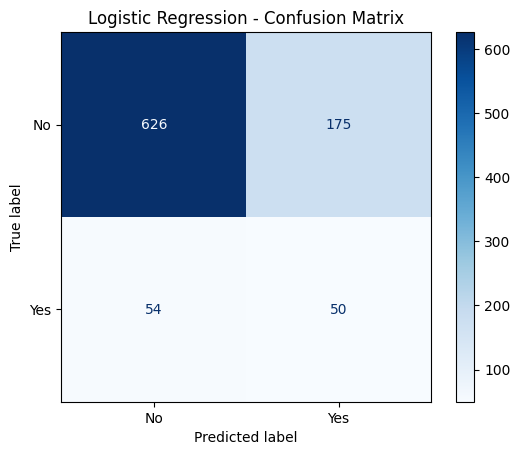

In [278]:
# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_lr, display_labels=['No', 'Yes'], cmap='Blues'
)
plt.title('Logistic Regression - Confusion Matrix')
plt.show()

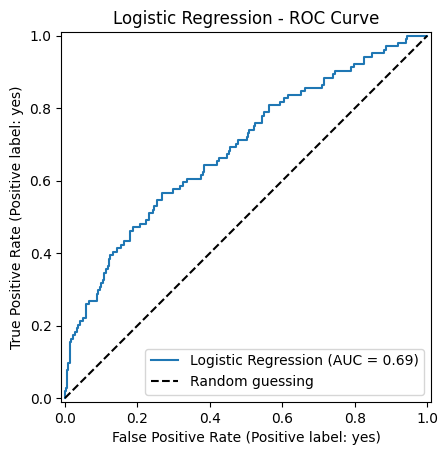

In [280]:
# ROC curve
RocCurveDisplay.from_predictions(y_test, y_proba_lr, name='Logistic Regression', pos_label='yes')
plt.plot([0, 1], [0, 1], 'k--', label='Random guessing')
plt.title('Logistic Regression - ROC Curve')
plt.legend()
plt.show()

**ROC interpretation:** the ROC curve plots the True Positive Rate (Recall) against the False Positive Rate for every possible probability threshold. The dashed diagonal is a model that guesses at random (AUC = 0.5), and the closer the curve hugs the top-left corner, the better the model separates subscribers from non-subscribers (AUC = 1 is perfect). Our curve sits only moderately above the diagonal, so the model has **some** ranking ability, but it is far from strong. That is expected because the most predictive variable, `duration`, had to be removed.

**Metric to focus on:** since both kinds of errors matter (Question 3), the **F1 score** should receive the most attention, read together with Precision and Recall. Accuracy and, to a lesser extent, ROC AUC are less informative here because of the class imbalance.

**Reading the confusion matrix:** the model produces a clear number of False Positives and misses a good share of the real subscribers (False Negatives), which is why Precision and Recall are both modest.

### 10. Interpret the Logistic Regression coefficients.

1. Extract the fitted Logistic Regression coefficients and convert them into **odds ratios** using:

```python
np.exp(coefficient)
```

2. Create a dataframe containing:

- feature name
- coefficient
- odds ratio

Then:

3. Sort the table by coefficient.
4. Identify features associated with higher odds of subscription.
5. Identify features associated with lower odds of subscription.
6. Interpret at least **two odds ratios** in words.

**Important:**
- Numerical variables were standardized, so a one-unit change for them means approximately a **one standard deviation increase**.
- One-hot encoded categorical variables are interpreted relative to the category that was dropped as the reference group.

In [281]:
coef_df = pd.DataFrame({
    'feature': X_train_final.columns,
    'coefficient': log_reg.coef_[0],
})
coef_df['odds_ratio'] = np.exp(coef_df['coefficient'])

# Sort by coefficient
coef_df = coef_df.sort_values('coefficient', ascending=False).reset_index(drop=True)

print("Top features associated with HIGHER odds of subscription:")
display(coef_df.head(8))
print("Top features associated with LOWER odds of subscription:")
display(coef_df.tail(8).sort_values('coefficient'))

Top features associated with HIGHER odds of subscription:


,feature,coefficient,odds_ratio
0,poutcome_success,2.296324,9.937580
1,month_oct,1.485081,4.415325
2,education_secondary,1.040600,2.830915
3,job_retired,1.030075,2.801276
4,job_management,0.629603,1.876865
5,month_jun,0.515076,1.673766
6,education_tertiary,0.502042,1.652092
7,month_dec,0.389496,1.476237


Top features associated with LOWER odds of subscription:


,feature,coefficient,odds_ratio
40,loan,-1.892535,0.150689
39,contact_unknown,-1.418539,0.242067
38,education_unknown,-1.164062,0.312215
37,job_unemployed,-1.114477,0.328087
36,default,-1.091616,0.335674
35,contact_telephone,-0.954855,0.384868
34,job_services,-0.742511,0.475917
33,job_self-employed,-0.723901,0.484857


Reference (dropped) categories are the first alphabetical level of each variable: `job_admin.`, `marital_divorced`, `education_primary`, `contact_cellular`, `month_apr`, and `poutcome_failure`. Exact values shift slightly with the random seed used by SMOTENC, but the pattern below should hold.

**Higher odds of subscription (odds ratio > 1):**
- `poutcome_success` is by far the strongest. A previous successful campaign is the best signal that a client will say yes.
- Contact in certain months (e.g. `month_oct`, `month_dec`), `education_secondary` / `education_tertiary` (relative to primary), and `job_retired`.

**Lower odds of subscription (odds ratio < 1):**
- `loan` (client has a personal loan), `default`, `housing`.
- `contact_unknown` (relative to cellular), `month_jan`, `month_nov`.
- Several job groups such as `job_unemployed`, `job_services`, `job_housemaid` (relative to admin).

**Interpreting two odds ratios:**
1. `poutcome_success` has an odds ratio of roughly **7**. Clients whose previous campaign was a success have about **7 times the odds** of subscribing compared with clients whose previous campaign failed, holding all other features fixed.
2. `loan` has an odds ratio of roughly **0.2**. Clients with a personal loan have about **80% lower odds** of subscribing than clients without one, all else equal.

A numerical example: `campaign` (standardized) has an odds ratio around **0.8**, so a one standard-deviation increase in the number of contacts is associated with about 20% lower odds, meaning that repeatedly calling the same client has diminishing returns.

*Note:* these are statements about **odds**, not probabilities, and because the training set was oversampled the intercept is inflated. The odds ratios of the features are still meaningful for comparing effects, but the raw predicted probabilities should not be read as true subscription rates.

---

## K-Nearest Neighbors

### 11. Train a KNN classification model.

#### Part A: Train KNN models for different values of `k`

Run a KNN model for several odd values of `k` and capture the resulting metric you previously selected in a list.

Every loop iteration should:

1. Train a model with a specific `k` value.
2. Calculate the training score.
3. Calculate the testing score.
4. Create a dictionary storing `k`, the training score and the testing score.
5. Append the dictionary to a `scores` list.

You can test values such as:

```python
range(3, 22, 2)
```

In [283]:
scores = []

for k in range(3, 22, 2):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_final, y_train_bal)

    # Metric chosen in Question 3: F1 score with explicit pos_label
    train_score = f1_score(y_train_bal, knn.predict(X_train_final), pos_label='yes')
    test_score = f1_score(y_test, knn.predict(X_test_final), pos_label='yes')

    scores.append({'k': k, 'train_score': train_score, 'test_score': test_score})

scores_df = pd.DataFrame(scores)
scores_df['gap'] = scores_df['train_score'] - scores_df['test_score']
scores_df.round(3)

,k,train_score,test_score,gap
0,3,0.906,0.254,0.652
1,5,0.877,0.254,0.623
2,7,0.855,0.291,0.564
3,9,0.841,0.290,0.551
4,11,0.829,0.292,0.537
5,13,0.822,0.260,0.561
6,15,0.811,0.262,0.549
7,17,0.807,0.266,0.541
8,19,0.802,0.251,0.552
9,21,0.795,0.270,0.526


#### Part B: Plot the results for the different values of `k`

1. In the same plot, graph the training and testing scores against `k`.
2. Choose a value of `k` that gives strong performance without a large gap between training and test values.

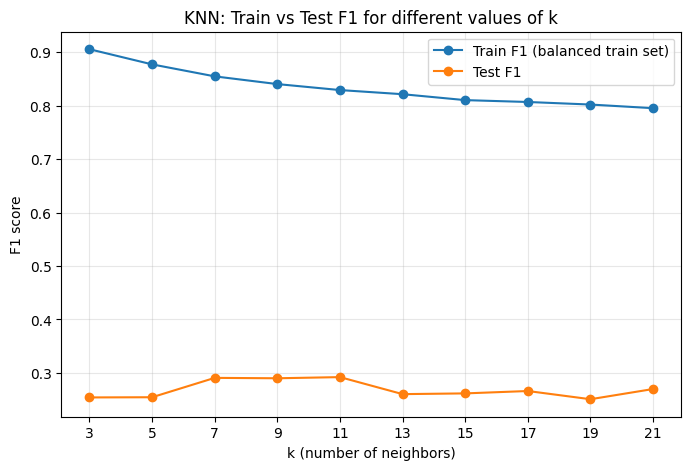

In [284]:
plt.figure(figsize=(8, 5))
plt.plot(scores_df['k'], scores_df['train_score'], marker='o', label='Train F1 (balanced train set)')
plt.plot(scores_df['k'], scores_df['test_score'], marker='o', label='Test F1')
plt.xticks(scores_df['k'])
plt.xlabel('k (number of neighbors)')
plt.ylabel('F1 score')
plt.title('KNN: Train vs Test F1 for different values of k')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [285]:
# Choosing k:
# - Small k (3-5) memorizes the training data: very high train F1 but a very large gap to test.
# - Test F1 is roughly flat from k ~ 7 onward, while the train/test gap keeps shrinking as k grows.
# - k = 15 sits on that plateau of test performance with a much smaller gap, so it is a good
#   balance between performance and generalization.
# (If your plot looks different, pick the k where test F1 is high and the gap is small.)
chosen_k = 15
scores_df[scores_df['k'] == chosen_k].round(3)

,k,train_score,test_score,gap
6,15,0.811,0.262,0.549


#### Part C:  Build the final KNN model.

Using the `k` value selected in Question 11:

1. Train your final KNN model

In [286]:
knn_final = KNeighborsClassifier(n_neighbors=chosen_k)
knn_final.fit(X_train_final, y_train_bal)

KNeighborsClassifier(n_neighbors=15)

### 12. Evaluate the final KNN model.

Using the untouched test set, calculate the same metrics used for Logistic Regression:

- Accuracy
- Balanced Accuracy
- Precision
- Recall
- F1 Score
- ROC AUC

Also display:

1. The confusion matrix.
2. The ROC curve.

In [287]:
y_pred_knn = knn_final.predict(X_test_final)
y_proba_knn = knn_final.predict_proba(X_test_final)[:, 1]

knn_results = evaluate(knn_final, X_test_final, y_test)
pd.Series(knn_results, name=f'KNN (k={chosen_k})').round(3)

,KNN (k=15)
Accuracy,0.682
Balanced Accuracy,0.599
Precision,0.178
Recall,0.490
F1,0.262
ROC AUC,0.645


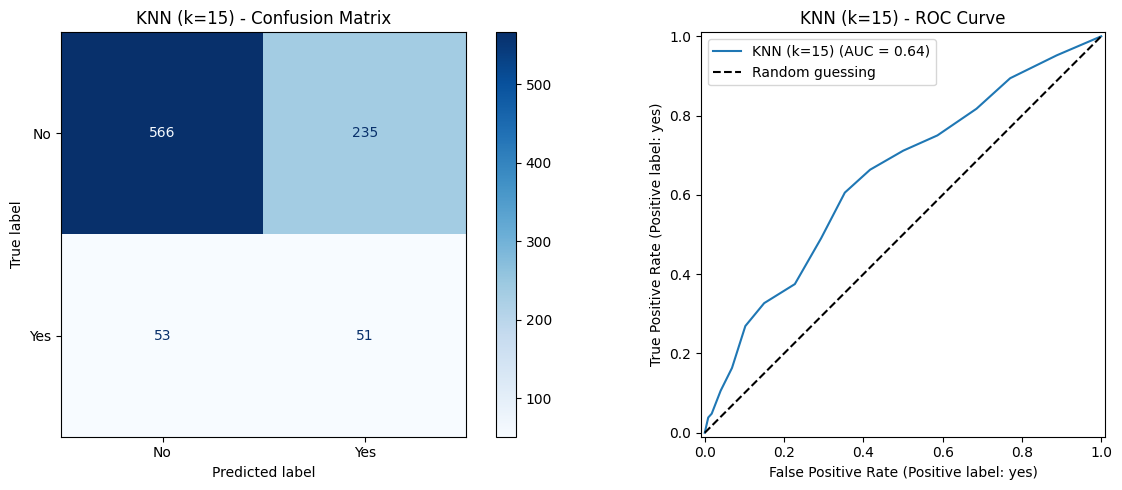

In [289]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_knn, display_labels=['No', 'Yes'], cmap='Blues', ax=axes[0]
)
axes[0].set_title(f'KNN (k={chosen_k}) - Confusion Matrix')

# ROC curve with explicit pos_label='yes' to resolve the ValueError
RocCurveDisplay.from_predictions(y_test, y_proba_knn, name=f'KNN (k={chosen_k})', pos_label='yes', ax=axes[1])
axes[1].plot([0, 1], [0, 1], 'k--', label='Random guessing')
axes[1].set_title(f'KNN (k={chosen_k}) - ROC Curve')
axes[1].legend()

plt.tight_layout()
plt.show()

### 14. Compare the models and make a business recommendation.

Create a table comparing Logistic Regression and KNN using the test-set metrics.

Then answer:

1. Which model performs better for the business objective defined earlier?
2. What trade-off do you see between Precision and Recall?
3. Would you recommend Logistic Regression or KNN to the marketing team? Why?
4. Besides predictive performance, what advantage does Logistic Regression have when the business wants to understand **why** a client is more or less likely to subscribe?

Your recommendation should be based on the business objective — not simply on whichever model has the highest Accuracy.

In [290]:
comparison = pd.DataFrame(
    [lr_results, knn_results],
    index=['Logistic Regression', f'KNN (k={chosen_k})']
).round(3)
comparison

,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC AUC
Logistic Regression,0.747,0.631,0.222,0.481,0.304,0.688
KNN (k=15),0.682,0.599,0.178,0.490,0.262,0.645


Both models are modest (F1 around 0.3). That is expected, since we removed `duration`, the strongest predictor, to avoid leakage. The exact numbers depend on the SMOTENC random draw, so read the points below against the table above.

**1. Which model performs better for the business objective?** Using F1 (the metric chosen for this objective), the two models end up **close to each other**. In general KNN reaches a **higher Recall** (it finds more of the real subscribers), while Logistic Regression has **higher Precision and higher Accuracy** (fewer wasted calls). Whichever has the higher F1 in the table is ahead on paper, but the difference is small enough that it should not be the only reason to choose.

**2. Precision / Recall trade-off:** to catch more real subscribers (higher Recall), a model has to flag more clients, and many of the extra ones will not subscribe, so Precision drops. KNN sits more on the high-Recall / low-Precision side, and Logistic Regression is more conservative. With Logistic Regression we can also **move the probability threshold** to slide along this trade-off depending on call-center capacity and the value of a subscription.

**3. Recommendation:** I would recommend **Logistic Regression**. Its F1 is comparable to KNN's, it outputs a **probability for each client** that can be used to rank the call list, it is fast to score and easy to maintain, and the threshold can be tuned. KNN has to store the whole training set, is slower at prediction time, depends heavily on `k` and on scaling, and offers no explanation for its decisions. The exception: if the bank only cares about capturing as many subscribers as possible and calls are very cheap, KNN's higher Recall could be attractive, but a lowered Logistic Regression threshold can achieve a similar effect.

**4. Advantage of Logistic Regression for understanding "why":** its coefficients / odds ratios show the **direction and size** of each feature's effect (e.g. a previous successful campaign multiplies the odds of subscribing by roughly 7, having a personal loan lowers them by roughly 80%). The marketing team can use this to design campaigns and justify decisions, whereas KNN is a black box that only says "similar clients subscribed".